# The Hitchhiker’s Guide to Feature Extraction

[Reference](https://www.kdnuggets.com/2019/06/hitchhikers-guide-feature-extraction.html)

Ignore the warning about importing a deprecated module.

**Note**: the original article was written in June 2019 and some of the code had to be adapted to be run in October 2026.

The [Jupyter notebook](https://www.kaggle.com/code/mlwhiz/feature-creation/notebook) provided by the author can't be run as it uses deprecated modules and functions.

First, we load the data as explained in [feature tools documentation](https://featuretools.alteryx.com/en/stable/)

In [1]:
import featuretools as ft
from woodwork.logical_types import PostalCode, Categorical
# Importing Latex is required to display when exporting to PDF via nbconvert
from IPython.display import display, Markdown, Image, Latex
import numpy as np
import pandas as pd
import warnings
from time import perf_counter

# Load the mock customer data from featuretools
data = ft.demo.load_mock_customer()

/Users/alvaro/PycharmProjects/IATD-Machine-Learning-Algorithms/.venv/lib/python3.12/site-packages/woodwork/__init__.py:2: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


In [2]:
customers_df = data["customers"]
customers_df

,customer_id,zip_code,join_date,birthday
0,1,60091,2011-04-17 10:48:33,1994-07-18
1,2,13244,2012-04-15 23:31:04,1986-08-18
2,3,13244,2011-08-13 15:42:34,2003-11-21
3,4,60091,2011-04-08 20:08:14,2006-08-15
4,5,60091,2010-07-17 05:27:50,1984-07-28


In [3]:
sessions_df = data["sessions"]
sessions_df.sample(5)

,session_id,customer_id,device,session_start
13,14,1,tablet,2014-01-01 03:28:00
6,7,3,tablet,2014-01-01 01:39:40
1,2,5,mobile,2014-01-01 00:17:20
28,29,1,mobile,2014-01-01 07:10:05
24,25,3,desktop,2014-01-01 05:59:40


In [4]:
transactions_df = data["transactions"]
transactions_df.sample(5)

,transaction_id,session_id,transaction_time,product_id,amount
74,232,5,2014-01-01 01:20:10,1,139.20
231,27,17,2014-01-01 04:10:15,2,90.79
434,36,31,2014-01-01 07:50:10,3,62.35
420,56,30,2014-01-01 07:35:00,3,72.70
54,444,4,2014-01-01 00:58:30,4,43.59


In [5]:
print(f"Customers: {len(customers_df)}, Sessions: {len(sessions_df)}, Transactions: {len(transactions_df)}")

Customers: 5, Sessions: 35, Transactions: 500


Then we can continue reading the article.

## 1. Automatic Feature Creation using featuretools:

Have you read about featuretools yet? If not, then you are going to be delighted.

Featuretools is a framework to perform automated feature engineering. It excels at transforming temporal and relational datasets into feature matrices for machine learning.

How? Let us work with a toy example to show you the power of featuretools.

Let us say that we have three tables in our database: **Customers, Sessions, and Transactions**.

![Data relationships](./images/reference/featuretools_data_relationships.png)

In [6]:
customers_df.head()

,customer_id,zip_code,join_date,birthday
0,1,60091,2011-04-17 10:48:33,1994-07-18
1,2,13244,2012-04-15 23:31:04,1986-08-18
2,3,13244,2011-08-13 15:42:34,2003-11-21
3,4,60091,2011-04-08 20:08:14,2006-08-15
4,5,60091,2010-07-17 05:27:50,1984-07-28


In [7]:
sessions_df.head()

,session_id,customer_id,device,session_start
0,1,2,desktop,2014-01-01 00:00:00
1,2,5,mobile,2014-01-01 00:17:20
2,3,4,mobile,2014-01-01 00:28:10
3,4,1,mobile,2014-01-01 00:44:25
4,5,4,mobile,2014-01-01 01:11:30


In [8]:
transactions_df.head()

,transaction_id,session_id,transaction_time,product_id,amount
0,298,1,2014-01-01 00:00:00,5,127.64
1,2,1,2014-01-01 00:01:05,2,109.48
2,308,1,2014-01-01 00:02:10,3,95.06
3,116,1,2014-01-01 00:03:15,4,78.92
4,371,1,2014-01-01 00:04:20,3,31.54


So without further ado, let us create an empty entityset. I just gave the name as customers. You can use any name here. It is just an empty bucket right now.

In [9]:
# Create new entityset
es = ft.EntitySet(id = 'customers')

Let us add our dataframes to it. The order of adding dataframes is not important. To add a dataframe to an existing entityset, we do the below operation.

In [10]:
# Create an entity from the customers dataframe

'''
DEPRECATED
es = es.entity_from_dataframe(entity_id = 'customers', dataframe = customers_df, index = 'customer_id', time_index = 'join_date' ,variable_types = {"zip_code": ft.variable_types.ZIPCode})
'''

# new way to create an entity from the customers dataframe
es = es.add_dataframe(
    dataframe_name="customers",
    dataframe=customers_df,
    index="customer_id",
    time_index="join_date",
    logical_types={"zip_code": PostalCode},
)

In [11]:
es

Entityset: customers
  DataFrames:
    customers [Rows: 5, Columns: 4]
  Relationships:
    No relationships

In [12]:
feature_matrix, feature_defs = ft.dfs(
        entityset=es,
        target_dataframe_name="customers",
        max_depth=2,
    )

print(f"So far we have {len(feature_defs)} features in the entity set.")


So far we have 9 features in the entity set.


/Users/alvaro/PycharmProjects/IATD-Machine-Learning-Algorithms/.venv/lib/python3.12/site-packages/featuretools/synthesis/deep_feature_synthesis.py:169: UserWarning: Only one dataframe in entityset, changing max_depth to 1 since deeper features cannot be created
  warnings.warn(


Let us add all our dataframes:

In [13]:
'''
DEPRECATED
# adding the transactions_df
es = es.entity_from_dataframe(entity_id="transactions",
                                 dataframe=transactions_df,
                                 index="transaction_id",
                               time_index="transaction_time",
                               variable_types={"product_id": ft.variable_types.Categorical})

# adding sessions_df
es = es.entity_from_dataframe(entity_id="sessions",
            dataframe=sessions_df,
            index="session_id", time_index = 'session_start')
'''

# Add transactions
es = es.add_dataframe(
    dataframe_name="transactions",
    dataframe=transactions_df,
    index="transaction_id",
    time_index="transaction_time",
    logical_types={"product_id": Categorical},
)

# Add sessions
es = es.add_dataframe(
    dataframe_name="sessions",
    dataframe=sessions_df,
    index="session_id",
    time_index="session_start",
    logical_types={"device": Categorical}, # This prevents the warning 'UserWarning: Could not infer format, so each element will be parsed individually, falling back to dateutil.'
)

In [14]:
es

Entityset: customers
  DataFrames:
    customers [Rows: 5, Columns: 4]
    transactions [Rows: 500, Columns: 5]
    sessions [Rows: 35, Columns: 4]
  Relationships:
    No relationships

All three dataframes but no relationships. By relationships, I mean that my bucket doesn’t know that customer_id in customers_df and session_df are the same columns.

We can provide this information to our entityset as:

**Note**: as can be seen in the new Feature Tools documentation creating a Deep Feature Synthesis (DFS) with all the dataframes and relationships can be done in a much simpler way:

```python
dataframes = {
    "customers": (customers_df, "customer_id"),
    "sessions": (sessions_df, "session_id", "session_start"),
    "transactions": (transactions_df, "transaction_id", "transaction_time"),
}

relationships = [
    ("sessions", "session_id", "transactions", "session_id"),
    ("customers", "customer_id", "sessions", "customer_id"),
]

feature_matrix_customers, features_defs = ft.dfs(
    dataframes=dataframes,
    relationships=relationships,
    target_dataframe_name="customers",
)
feature_matrix_customers
```

In [15]:
'''
DEPRECATED
# adding the customer_id relationship
cust_relationship = ft.Relationship(es["customers"]["customer_id"],
                       es["sessions"]["customer_id"])

# Add the relationship to the entity set
es = es.add_relationship(cust_relationship)

# adding the session_id relationship
sess_relationship = ft.Relationship(es["sessions"]["session_id"],
                       es["transactions"]["session_id"])

# Add the relationship to the entity set
es = es.add_relationship(sess_relationship)
'''

# One customer → many sessions
es = es.add_relationship(
    parent_dataframe_name="customers",
    parent_column_name="customer_id",
    child_dataframe_name="sessions",
    child_column_name="customer_id",
)

# One session → many transactions
es = es.add_relationship(
    parent_dataframe_name="sessions",
    parent_column_name="session_id",
    child_dataframe_name="transactions",
    child_column_name="session_id",
)

es

Entityset: customers
  DataFrames:
    customers [Rows: 5, Columns: 4]
    transactions [Rows: 500, Columns: 5]
    sessions [Rows: 35, Columns: 4]
  Relationships:
    sessions.customer_id -> customers.customer_id
    transactions.session_id -> sessions.session_id

We can see the datasets as well as the relationships. Most of our work here is done. We are ready to cook features.

In [16]:
# DEPRECATED: feature_matrix, feature_defs = ft.dfs(entityset=es, target_entity="customers",max_depth = 2)

with warnings.catch_warnings():
    # Suppress the FutureWarning about SeriesGroupBy in featuretools
    warnings.filterwarnings(
        "ignore",
        message=r"The provided callable .* is currently using SeriesGroupBy\.",
        category=FutureWarning,
    )
    feature_matrix, feature_defs = ft.dfs(
        entityset=es,
        target_dataframe_name="customers",
        max_depth=2,
    )

feature_matrix.head()

,zip_code,COUNT(sessions),MODE(sessions.device),NUM_UNIQUE(sessions.device),COUNT(transactions),MAX(transactions.amount),MEAN(transactions.amount),MIN(transactions.amount),MODE(transactions.product_id),NUM_UNIQUE(transactions.product_id),...,STD(sessions.SKEW(transactions.amount)),STD(sessions.SUM(transactions.amount)),SUM(sessions.MAX(transactions.amount)),SUM(sessions.MEAN(transactions.amount)),SUM(sessions.MIN(transactions.amount)),SUM(sessions.NUM_UNIQUE(transactions.product_id)),SUM(sessions.SKEW(transactions.amount)),SUM(sessions.STD(transactions.amount)),MODE(transactions.sessions.device),NUM_UNIQUE(transactions.sessions.device)
customer_id,,,,,,,,,,,,,,,,,,,,,
5,60091,6,mobile,3,79,149.02,80.375443,7.55,5,5,...,0.415426,402.775486,839.76,472.231119,86.49,30.0,0.014384,259.873954,mobile,3
4,60091,8,mobile,3,109,149.95,80.070459,5.73,2,5,...,0.387884,235.992478,1157.99,649.657515,131.51,37.0,0.002764,356.125829,mobile,3
1,60091,8,mobile,3,126,139.43,71.631905,5.81,4,5,...,0.589386,279.510713,1057.97,582.193117,78.59,40.0,-0.476122,312.745952,mobile,3
3,13244,6,desktop,3,93,149.15,67.060430,5.89,1,5,...,0.429374,219.021420,847.63,405.237462,66.21,29.0,2.286086,257.299895,desktop,3
2,13244,7,desktop,3,93,146.81,77.422366,8.73,4,5,...,0.509798,251.609234,931.63,548.905851,154.60,35.0,-0.277640,258.700528,desktop,3


In [17]:
feature_matrix.columns.tolist()

['zip_code',
 'COUNT(sessions)',
 'MODE(sessions.device)',
 'NUM_UNIQUE(sessions.device)',
 'COUNT(transactions)',
 'MAX(transactions.amount)',
 'MEAN(transactions.amount)',
 'MIN(transactions.amount)',
 'MODE(transactions.product_id)',
 'NUM_UNIQUE(transactions.product_id)',
 'SKEW(transactions.amount)',
 'STD(transactions.amount)',
 'SUM(transactions.amount)',
 'DAY(birthday)',
 'DAY(join_date)',
 'MONTH(birthday)',
 'MONTH(join_date)',
 'WEEKDAY(birthday)',
 'WEEKDAY(join_date)',
 'YEAR(birthday)',
 'YEAR(join_date)',
 'MAX(sessions.COUNT(transactions))',
 'MAX(sessions.MEAN(transactions.amount))',
 'MAX(sessions.MIN(transactions.amount))',
 'MAX(sessions.NUM_UNIQUE(transactions.product_id))',
 'MAX(sessions.SKEW(transactions.amount))',
 'MAX(sessions.STD(transactions.amount))',
 'MAX(sessions.SUM(transactions.amount))',
 'MEAN(sessions.COUNT(transactions))',
 'MEAN(sessions.MAX(transactions.amount))',
 'MEAN(sessions.MEAN(transactions.amount))',
 'MEAN(sessions.MIN(transactions.amo

In [18]:
print(f"Now we have {len(feature_defs)} features in the entity set.")

Now we have 75 features in the entity set.


In the original [tutorial](https://www.kdnuggets.com/2019/06/hitchhikers-guide-feature-extraction.html) generates 73 features, whereas this notebook generates 75. This difference may be due to changes in Featuretools since the tutorial was published in 2019. This notebook uses Featuretools 1.31.0.

In [19]:
results = {}
summary = []

for depth in [2, 3]:
    start = perf_counter()

    with warnings.catch_warnings():
        warnings.filterwarnings(
            "ignore",
            message=r"The provided callable",
            category=FutureWarning,
        )

        matrix, definitions = ft.dfs(
            entityset=es,
            target_dataframe_name="customers",
            max_depth=depth,
        )

    results[depth] = (matrix, definitions)
    summary.append({
        "Max depth": depth,
        "Number of features": len(definitions),
        "Elapsed seconds": perf_counter() - start,
    })

display(pd.DataFrame(summary))

,Max depth,Number of features,Elapsed seconds
0,2,75,0.058741
1,3,115,0.078879


Then inspect **only the features added at depth 3:**

In [20]:
names_depth_2 = {f.get_name() for f in results[2][1]}

new_features = [
    f.get_name()
    for f in results[3][1]
    if f.get_name() not in names_depth_2
]

print(f"{len(new_features)} additional features:")
for name in new_features:
    print(name)

40 additional features:
MODE(transactions.DAY(transaction_time))
MODE(transactions.MONTH(transaction_time))
MODE(transactions.WEEKDAY(transaction_time))
MODE(transactions.YEAR(transaction_time))
NUM_UNIQUE(transactions.DAY(transaction_time))
NUM_UNIQUE(transactions.MONTH(transaction_time))
NUM_UNIQUE(transactions.WEEKDAY(transaction_time))
NUM_UNIQUE(transactions.YEAR(transaction_time))
MAX(sessions.NUM_UNIQUE(transactions.DAY(transaction_time)))
MAX(sessions.NUM_UNIQUE(transactions.MONTH(transaction_time)))
MAX(sessions.NUM_UNIQUE(transactions.WEEKDAY(transaction_time)))
MAX(sessions.NUM_UNIQUE(transactions.YEAR(transaction_time)))
MEAN(sessions.NUM_UNIQUE(transactions.DAY(transaction_time)))
MEAN(sessions.NUM_UNIQUE(transactions.MONTH(transaction_time)))
MEAN(sessions.NUM_UNIQUE(transactions.WEEKDAY(transaction_time)))
MEAN(sessions.NUM_UNIQUE(transactions.YEAR(transaction_time)))
MIN(sessions.NUM_UNIQUE(transactions.DAY(transaction_time)))
MIN(sessions.NUM_UNIQUE(transactions.MONTH(

In [21]:
def display_feature(feature_name, depth=3):
    matrix, definitions = results[depth]

    feature = next(
        (f for f in definitions if f.get_name() == feature_name),
        None,
    )

    if feature is None:
        display(Markdown(f"**Feature not found:** `{feature_name}`"))
        return

    display(Markdown(f"### Feature\n\n`{feature_name}`"))

    display(Markdown("#### Calculation diagram"))
    # Better to make it vertical than horizontal, so it fits on the page
    graph = ft.graph_feature(feature)
    graph.attr(rankdir="TB")
    #display(graph) # Not compatible with nbconvert
    display(Image(data=graph.pipe(format="png")))

    display(Markdown("#### Description"))
    display(Markdown(ft.describe_feature(feature)))

    display(Markdown("#### Values by customer"))
    values = (
        matrix[[feature_name]]
        .sort_index()
        .rename(columns={feature_name: "Feature value"})
        .rename_axis("Customer ID") # To prevent LaTeX errors when exporting as it doesn't handle well the underscores.
    )

    display(values.style.format(precision=3, na_rep="—")) # Not LaTeX compatible: in the final document this will not be shown and only the code below.

    display(Latex(values.to_latex(
        float_format="%.3f",
        na_rep="—",
        escape=True,
    )))


### Feature

`MIN(sessions.NUM_UNIQUE(transactions.WEEKDAY(transaction_time)))`

#### Calculation diagram

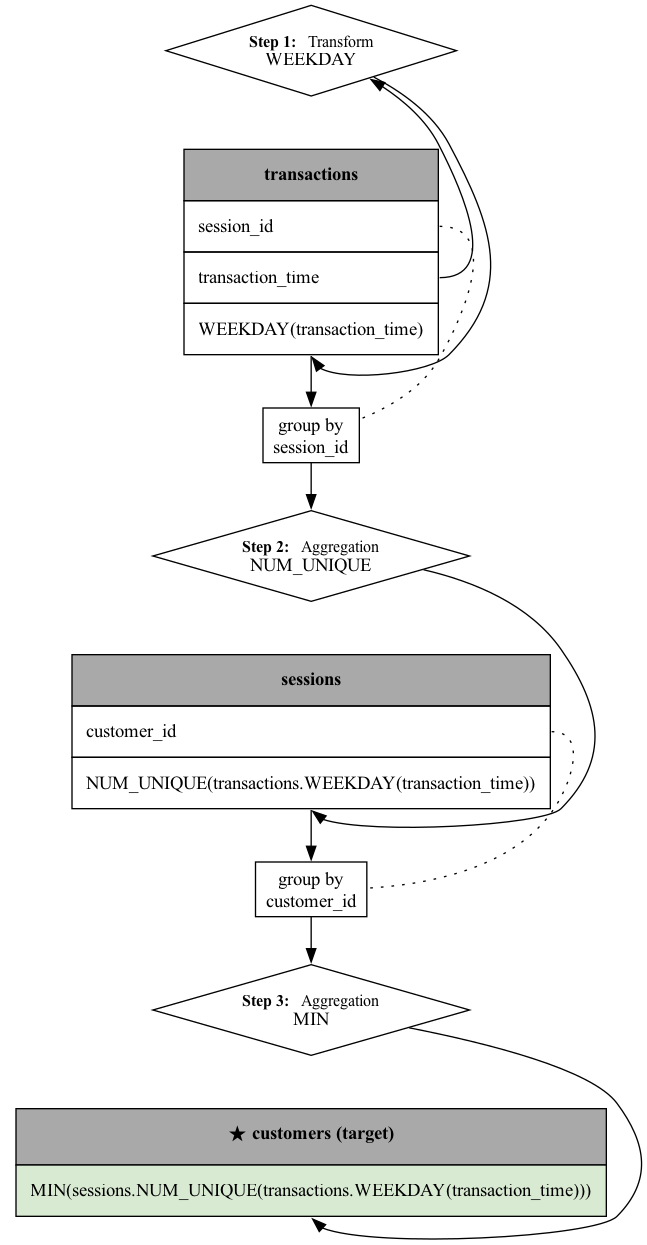

#### Description

The minimum of the number of unique elements in the day of the week of the "transaction_time" of all instances of "transactions" for each "session_id" in "sessions" of all instances of "sessions" for each "customer_id" in "customers".

#### Values by customer

,Feature value
Customer ID,
1,1.000
2,1.000
3,1.000
4,1.000
5,1.000


<IPython.core.display.Latex object>

In [22]:
feature_name = new_features[18]

display_feature(feature_name)

### Feature

`STD(sessions.NUM_UNIQUE(transactions.DAY(transaction_time)))`

#### Calculation diagram

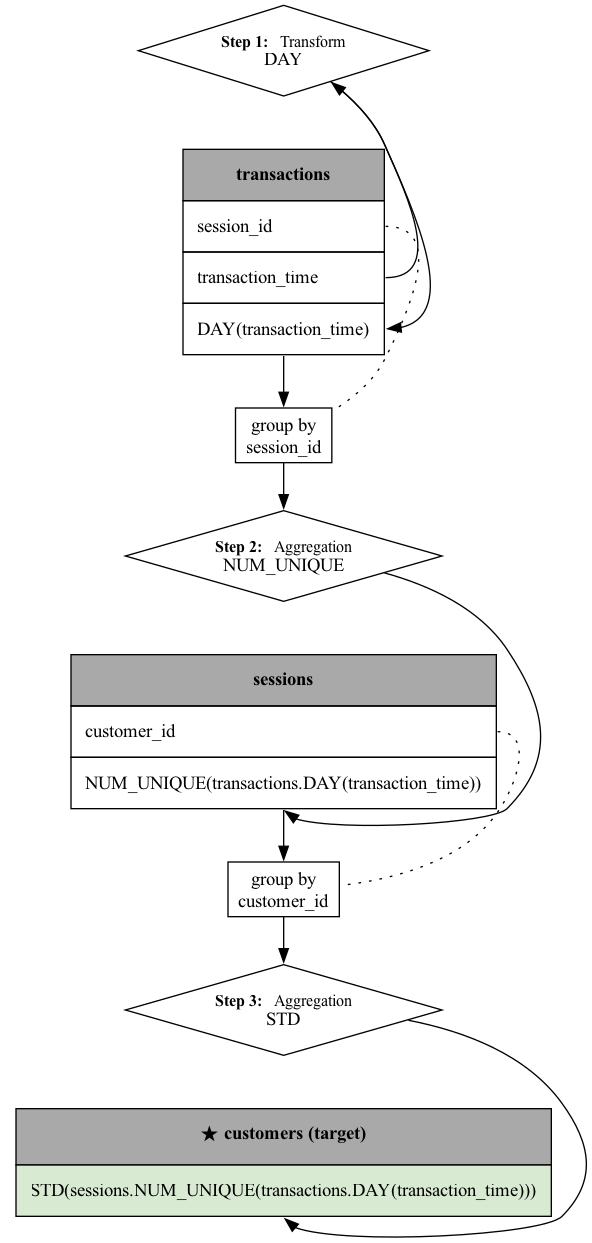

#### Description

The standard deviation of the number of unique elements in the day of the month of the "transaction_time" of all instances of "transactions" for each "session_id" in "sessions" of all instances of "sessions" for each "customer_id" in "customers".

#### Values by customer

,Feature value
Customer ID,
1,0.000
2,0.000
3,0.000
4,0.000
5,0.000


<IPython.core.display.Latex object>

In [23]:
display_feature(new_features[32])

This is a useful finding: **greater depth adds complexity, but doesn’t guarantee useful features.** Even features that vary still need evaluation to determine whether they help predict your target.

To check the article’s specific example and display its values.

Read that feature from the inside out:

1. YEAR extracts the year of each transaction.
2. NUM_UNIQUE counts distinct transaction years within each session.
3. MAX selects the largest of those session counts for each customer. `max_depth=3` allows up to three stacked operations, including transformations such as `YEAR`, not just aggregations. Timing is illustrative: caching and run-to-run variation can affect these small examples.

In [24]:
example = "MAX(sessions.NUM_UNIQUE(transactions.YEAR(transaction_time)))"

matrix_depth_3 = results[3][0]

if example in matrix_depth_3.columns:
    display(matrix_depth_3[[example]])
else:
    print("This feature was not generated with the current settings.")

,MAX(sessions.NUM_UNIQUE(transactions.YEAR(transaction_time)))
customer_id,
5,1.0
4,1.0
1,1.0
3,1.0
2,1.0


The same using pandas:

In [25]:
# 1. Extract the year of each transaction
transactions = transactions_df.assign(
    transaction_year=pd.to_datetime(
        transactions_df["transaction_time"]
    ).dt.year
)

print(f"There are {transactions['transaction_year'].nunique()} different transaction years in the dataset: {transactions['transaction_year'].unique()}")


# 2. Count distinct transaction years per session
years_per_session = (
    transactions.groupby("session_id")["transaction_year"]
    .nunique()
    .rename("unique_transaction_years")
)

print(f"There are {years_per_session.nunique()} different counts of unique transaction years per session: {years_per_session.unique()}")

# Attach these counts to sessions and their customers
sessions_with_counts = sessions_df[
    ["session_id", "customer_id"]
].merge(
    years_per_session,
    left_on="session_id",
    right_index=True,
    how="left",
    validate="one_to_one",
)

# Sessions without transactions have zero distinct years
sessions_with_counts["unique_transaction_years"] = (
    sessions_with_counts["unique_transaction_years"].fillna(0)
)

# 3. Find the maximum session count for each customer
pandas_feature = (
    sessions_with_counts.groupby("customer_id")["unique_transaction_years"]
    .max()
    .reindex(customers_df["customer_id"])
    .rename("max_unique_transaction_years")
)

display(pandas_feature.to_frame())

There are 1 different transaction years in the dataset: [2014]
There are 1 different counts of unique transaction years per session: [1]


,max_unique_transaction_years
customer_id,
5,1
4,1
1,1
3,1
2,1


**Depth-2 examples:**

In [26]:
with warnings.catch_warnings():
    warnings.filterwarnings(
        "ignore",
        message=r"The provided callable .* is currently using SeriesGroupBy\.",
        category=FutureWarning,
    )

    feature_matrix, feature_defs = ft.dfs(
        entityset=es,
        target_dataframe_name="customers",
        agg_primitives=["sum", "std"],
        trans_primitives=[],
        max_depth=2,
    )

examples = [
    "SUM(sessions.STD(transactions.amount))",
    "STD(sessions.SUM(transactions.amount))",
]

display(feature_matrix[examples].sort_index())

,SUM(sessions.STD(transactions.amount)),STD(sessions.SUM(transactions.amount))
customer_id,,
1,312.745952,279.510713
2,258.700528,251.609234
3,257.299895,219.021420
4,356.125829,235.992478
5,259.873954,402.775486


Using pandas:

In [27]:
session_stats = (
    transactions_df.groupby("session_id")["amount"]
    .agg(
        total_amount="sum",
        amount_std="std", # This doesn't work: amount_std=lambda values: values.std(ddof=0),
    )
    .reset_index()
)

# Match sessions by their actual IDs
session_stats = sessions_df[["session_id", "customer_id"]].merge(
    session_stats,
    on="session_id",
    how="left",
    validate="one_to_one",
)

session_stats["total_amount"] = session_stats["total_amount"].fillna(0)

# Note that this only displays 10 rows. We don't see all the rows for the same customer.
display(session_stats.head(10))

,session_id,customer_id,total_amount,amount_std
0,1,2,1229.01,41.600976
1,2,5,746.96,45.893591
2,3,4,1329.00,46.240016
3,4,1,1613.93,40.187205
4,5,4,777.02,48.918663
5,6,1,1266.60,42.654755
6,7,3,941.87,47.264797
7,8,4,1351.46,44.213242
8,9,1,1052.03,46.905665
9,10,2,1320.64,39.886614


In [28]:
# Session statistics for each customer
'''customer_features = (
    session_stats.groupby("customer_id")
    .agg(
        sum_of_session_stds=("amount_std", "sum"),
        std_of_session_totals=(
            "total_amount",
            lambda values: values.std(ddof=0),
        ),
    )
)'''
customer_features = (
    session_stats.groupby("customer_id")
    .agg(
        sum_of_session_stds=("amount_std", "sum"),
        std_of_session_totals=("total_amount", "std"),
    )
)

display(customer_features.sort_index())

,sum_of_session_stds,std_of_session_totals
customer_id,,
1,312.745952,279.510713
2,258.700528,251.609234
3,257.299895,219.021420
4,356.125829,235.992478
5,259.873954,402.775486


### Calculating depth-2 features with pandas

A depth-2 feature combines two successive operations. In these examples, we first aggregate **transactions into sessions**, then aggregate **sessions into customers**.

We calculate two features:

1. **Sum of session standard deviations:** how much transaction amounts vary within sessions, accumulated across a customer's sessions.
2. **Standard deviation of session totals:** how much a customer's total spending varies between sessions.

Although both use `sum` and `std`, changing their order produces different information.

#### 1. Calculate statistics for each session

```python
session_stats = (
    transactions_df.groupby("session_id")["amount"]
    .agg(
        total_amount="sum",
        amount_std="std", # amount_std=lambda values: values.std(ddof=0),
    )
    .reset_index()
)

# Match sessions by their actual IDs
session_stats = sessions_df[["session_id", "customer_id"]].merge(
    session_stats,
    on="session_id",
    how="left",
    validate="one_to_one",
)

session_stats["total_amount"] = session_stats["total_amount"].fillna(0)

display(session_stats.head(10))
```

The first operation groups transactions by `session_id` and calculates:

- **`total_amount`**: the sum of all transaction amounts in the session.
- **`amount_std`**: the population standard deviation of the session's transaction amounts.

The merge associates each session with its customer. A left join preserves sessions without transactions; their total spending is set to zero, while their standard deviation remains missing.

| Column | Meaning |
|---|---|
| `session_id` | Identifies the session |
| `customer_id` | Identifies the customer who owns the session |
| `total_amount` | Total spending during the session |
| `amount_std` | Variation in transaction amounts within the session |

#### 2. Aggregate session statistics by customer

```python
customer_features = (
    session_stats.groupby("customer_id")
    .agg(
        sum_of_session_stds=("amount_std", "sum"),
        std_of_session_totals=("total_amount", "std"),
    )
)

display(customer_features)
```

The output contains one row per customer represented in `sessions_df`, with two calculated features.

#### Feature A: Sum of session standard deviations

Featuretools expression:

```text
SUM(sessions.STD(transactions.amount))
```

Pandas output column:

```text
sum_of_session_stds
```

For each customer, this adds the standard deviations calculated within their sessions:

$$
A_c = \sum_{s \in S_c} \operatorname{std}(a_{s,1}, \ldots, a_{s,n_s})
$$

Here, $S_c$ is the customer's set of sessions, and $a_{s,i}$ is a transaction amount in session $s$.

**Interpretation:**

- A value of **zero** means there is no within-session variation among the observed transactions.
- A larger value indicates more accumulated within-session variation.
- The value also depends on the number of sessions: customers with more sessions have more values contributing to the sum.

This is **not** the standard deviation of all the customer's transactions pooled together, nor the average session standard deviation.

#### Feature B: Standard deviation of session totals

Featuretools expression:

```text
STD(sessions.SUM(transactions.amount))
```

Pandas output column:

```text
std_of_session_totals
```

For each customer, this calculates the standard deviation of their session spending totals:

$$
B_c = \operatorname{std}(T_{s_1}, \ldots, T_{s_m}),
\qquad
T_s = \sum_i a_{s,i}
$$

**Interpretation:**

- A value of **zero** means the customer spends the same total amount in every session.
- A larger value means spending totals vary more between sessions.
- This measures variation in session totals, regardless of how those totals are divided into individual transactions.

Both features use the same currency units as `amount`; they are not percentages.

#### Worked example

Suppose a customer has two sessions:

| Session | Transaction amounts | Session total | Population standard deviation |
|---|---|---:|---:|
| A | 10, 30 | 40 | 10 |
| B | 20, 20 | 40 | 0 |

The resulting customer features are:

| Feature | Calculation | Result |
|---|---|---:|
| Sum of session standard deviations | $10 + 0$ | 10 |
| Standard deviation of session totals | $\operatorname{std}(40, 40)$ | 0 |

Transaction amounts vary within session A, but the customer spends exactly the same total in both sessions.

Now consider another customer:

| Session | Transaction amounts | Session total | Population standard deviation |
|---|---|---:|---:|
| A | 10, 10 | 20 | 0 |
| B | 30, 30 | 60 | 0 |

Their features are:

| Feature | Calculation | Result |
|---|---|---:|
| Sum of session standard deviations | $0 + 0$ | 0 |
| Standard deviation of session totals | $\operatorname{std}(20, 60)$ | 20 |

Within each session, all transaction amounts are identical. However, total spending differs between sessions.

These examples show why the two features capture different aspects of customer behaviour.

#### Standard deviation: population versus sample

Both pandas aggregation steps now use `"std"`, which defaults to **sample standard deviation (`ddof=1`)**.

Standard deviation is calculated by summing the squared deviations from the mean, dividing by a denominator, and taking the square root:

- **Population standard deviation (`ddof=0`)** uses a denominator of $N$.
- **Sample standard deviation (`ddof=1`)** uses a denominator of $N - 1$.

Here, $N$ is the number of non-missing observations.

The distinction affects numerical results:

| Values | Population standard deviation (`ddof=0`) | Sample standard deviation (`ddof=1`) |
|---|---:|---:|
| 10, 30 | 10 | Approximately 14.14 |
| 20, 20 | 0 | 0 |
| A single value | 0 | Missing (`NaN`) |

Our current Featuretools execution uses pandas' `SeriesGroupBy.std`, whose default is `ddof=1`. Using `"std"` at both pandas aggregation levels therefore makes the results match when aligned by `customer_id`.

The worked examples above use **population standard deviation** for simplicity. To interpret them using the same convention as the code:

- The standard deviation of `[10, 30]` becomes approximately **14.14**, rather than 10.
- The standard deviation of `[20, 60]` becomes approximately **28.28**, rather than 20.
- The standard deviation of `[40, 40]` remains **0**.

Neither convention is deprecated. The important point is to use the same convention when comparing calculations.

#### Missing values and empty sessions

- Pandas standard deviation ignores missing transaction amounts.
- With sample standard deviation (`ddof=1`), a session needs at least **two valid transaction amounts**. Otherwise, its standard deviation is missing (`NaN`).
- Pandas `sum()` skips missing values and, by default, returns zero when all contributing values are missing.
- Therefore, a zero `sum_of_session_stds` can mean either that the available session standard deviations are zero or that **no valid session standard deviations exist**.
- In this implementation, sessions without transactions receive a total amount of zero. These zero totals contribute to `std_of_session_totals`.
- A customer with only one session has a missing `std_of_session_totals`, because sample standard deviation requires at least two valid session totals.
- Customers without sessions are absent from this grouped output.

These cases should be considered before interpreting a zero as evidence of consistent spending. A missing standard deviation means there are insufficient observations, not necessarily that there is no variation.

## 2. Handling Categorical Features: Label/Binary/Hashing and Target/Mean Encoding

Creating automated features has its perks. But why would we data scientists be required if a simple library could do all our work?

This is the section where I will talk about handling categorical features.

### One hot encoding

In [29]:
sessions_df["device"].value_counts()

device
desktop    14
mobile     13
tablet      8
Name: count, dtype: int64

We can use **One hot encoding** to encode our categorical features. So if we have n levels in a category, we will get n-1 features.

In our sessions_df table, we have a column named device, which contains three levels — desktop, mobile, or tablet. We can get two columns from such a column using:

In [30]:
pd.get_dummies(sessions_df['device'],drop_first=True)

,mobile,tablet
1,False,False
2,True,False
3,True,False
4,True,False
5,True,False
6,False,True
7,False,True
8,False,True
9,False,False
10,False,True


### OrdinalEncoding

Sometimes there is an order associated with categories. In such a case, I usually use a simple map/apply function in pandas to create a new ordinal column.

For example, if I had a dataframe containing temperature as three levels: high medium and low, I would encode that as:

In [31]:
df = pd.DataFrame({
    "City": ["London", "New York", "Dubai"],
    "Temperature": ["low", "medium", "high"],
})

In [32]:
map_dict = {'low':0,'medium':1,'high':2}
def map_values(x):
    return map_dict[x]
df['Temperature_oe'] = df['Temperature'].apply(lambda x: map_values(x))

df

,City,Temperature,Temperature_oe
0,London,low,0
1,New York,medium,1
2,Dubai,high,2


### LabelEncoder

We could also have used **LabelEncoder** to encode our variable to numbers. What a label encoder essentially does is that it sees the first value in the column and converts it to 0, next value to 1 and so on. This approach works reasonably well with tree models, and I end up using it when I have a lot of levels in the categorical variable. We can use this as:

In [33]:
from sklearn.preprocessing import LabelEncoder
# create a labelencoder object
le = LabelEncoder()
# fit and transform on the data
sessions_df['device_le'] = le.fit_transform(sessions_df['device'])
sessions_df.head()

,session_id,customer_id,device,session_start,device_le
1,1,2,desktop,2014-01-01 00:00:00,0
2,2,5,mobile,2014-01-01 00:17:20,1
3,3,4,mobile,2014-01-01 00:28:10,1
4,4,1,mobile,2014-01-01 00:44:25,1
5,5,4,mobile,2014-01-01 01:11:30,1


### BinaryEncoder

BinaryEncoder is another method that one can use to encode categorical variables. It is an excellent method to use if you have many levels in a column. While we can encode a column with 1024 levels using 1023 columns using One Hot Encoding, using Binary encoding we can do it by just using ten columns.

Example created by Codex:

In [34]:
players = pd.DataFrame({
    "Player": [
        "Alex Smith", "Leo Martin", "Omar Hassan", "Lucas Silva",
        "Noah Brown", "Hugo Garcia", "Adam Wilson", "Marco Rossi",
    ],
    "Club": [
        "Arsenal", "Barcelona", "Chelsea", "Juventus",
        "Arsenal", "Real Madrid", "Chelsea", "Barcelona",
    ],
    "Age": [22, 25, 28, 24, 21, 30, 26, 23],
})

players

,Player,Club,Age
0,Alex Smith,Arsenal,22
1,Leo Martin,Barcelona,25
2,Omar Hassan,Chelsea,28
3,Lucas Silva,Juventus,24
4,Noah Brown,Arsenal,21
5,Hugo Garcia,Real Madrid,30
6,Adam Wilson,Chelsea,26
7,Marco Rossi,Barcelona,23


In [35]:
from category_encoders.binary import BinaryEncoder
# create a Binaryencoder object
be = BinaryEncoder(cols = ['Club'])
# fit and transform on the data
players_encoded = be.fit_transform(players)

players_encoded

,Player,Club_0,Club_1,Club_2,Age
0,Alex Smith,0,0,1,22
1,Leo Martin,0,1,0,25
2,Omar Hassan,0,1,1,28
3,Lucas Silva,1,0,0,24
4,Noah Brown,0,0,1,21
5,Hugo Garcia,1,0,1,30
6,Adam Wilson,0,1,1,26
7,Marco Rossi,0,1,0,23


Let us say we have a column in our FIFA 19 player data that contains all club names. This column has 652 unique values. One Hot encoding means creating 651 columns that would mean a lot of memory usage and a lot of sparse columns.

If we use Binary encoder, we will only need ten columns as $2^9<652 <2^{10}$.

We can binaryEncode this variable easily by using BinaryEncoder object from category_encoders:

Note: the dataset [fifa19.csv](https://www.kaggle.com/datasets/flop71/fifa19csv) is found in Kaggle.

Note that the first column of the dataset is an index column, so we will use `index_col=0` to avoid creating a new index column.

In [36]:
players = pd.read_csv("./data/week_2_fifa19.csv", index_col=0)

players.head()

,ID,Name,Age,Photo,Nationality,Flag,Overall,Potential,Club,Club Logo,...,Composure,Marking,StandingTackle,SlidingTackle,GKDiving,GKHandling,GKKicking,GKPositioning,GKReflexes,Release Clause
0,158023,L. Messi,31,https://cdn.sofifa.org/players/4/19/158023.png,Argentina,https://cdn.sofifa.org/flags/52.png,94,94,FC Barcelona,https://cdn.sofifa.org/teams/2/light/241.png,...,96.0,33.0,28.0,26.0,6.0,11.0,15.0,14.0,8.0,€226.5M
1,20801,Cristiano Ronaldo,33,https://cdn.sofifa.org/players/4/19/20801.png,Portugal,https://cdn.sofifa.org/flags/38.png,94,94,Juventus,https://cdn.sofifa.org/teams/2/light/45.png,...,95.0,28.0,31.0,23.0,7.0,11.0,15.0,14.0,11.0,€127.1M
2,190871,Neymar Jr,26,https://cdn.sofifa.org/players/4/19/190871.png,Brazil,https://cdn.sofifa.org/flags/54.png,92,93,Paris Saint-Germain,https://cdn.sofifa.org/teams/2/light/73.png,...,94.0,27.0,24.0,33.0,9.0,9.0,15.0,15.0,11.0,€228.1M
3,193080,De Gea,27,https://cdn.sofifa.org/players/4/19/193080.png,Spain,https://cdn.sofifa.org/flags/45.png,91,93,Manchester United,https://cdn.sofifa.org/teams/2/light/11.png,...,68.0,15.0,21.0,13.0,90.0,85.0,87.0,88.0,94.0,€138.6M
4,192985,K. De Bruyne,27,https://cdn.sofifa.org/players/4/19/192985.png,Belgium,https://cdn.sofifa.org/flags/7.png,91,92,Manchester City,https://cdn.sofifa.org/teams/2/light/10.png,...,88.0,68.0,58.0,51.0,15.0,13.0,5.0,10.0,13.0,€196.4M


In [37]:
clubs = players['Club'].unique()

print(f"There are {len(clubs)} unique clubs in the dataset.")

There are 652 unique clubs in the dataset.


In [38]:
# create a Binaryencoder object
be = BinaryEncoder(cols = ['Club'])
# fit and transform on the data
clubs_encoded = be.fit_transform(players)

binary_cols = [
    f"Club_{i}" for i in range(20)
    if f"Club_{i}" in clubs_encoded.columns
]

comparison = pd.concat(
    [players[["Club"]], clubs_encoded[binary_cols]],
    axis=1,
)

with pd.option_context("display.max_columns", None):
    display(comparison.head(10))

,Club,Club_0,Club_1,Club_2,Club_3,Club_4,Club_5,Club_6,Club_7,Club_8,Club_9
0,FC Barcelona,0,0,0,0,0,0,0,0,0,1
1,Juventus,0,0,0,0,0,0,0,0,1,0
2,Paris Saint-Germain,0,0,0,0,0,0,0,0,1,1
3,Manchester United,0,0,0,0,0,0,0,1,0,0
4,Manchester City,0,0,0,0,0,0,0,1,0,1
5,Chelsea,0,0,0,0,0,0,0,1,1,0
6,Real Madrid,0,0,0,0,0,0,0,1,1,1
7,FC Barcelona,0,0,0,0,0,0,0,0,0,1
8,Real Madrid,0,0,0,0,0,0,0,1,1,1
9,Atlético Madrid,0,0,0,0,0,0,1,0,0,0


There are **652 unique clubs** in the dataset. Binary encoding requires **10 bits** to represent them because:

- 9 bits provide $2^9 = 512$ combinations, which is insufficient.
- 10 bits provide $2^{10} = 1024$ combinations, which is sufficient.

Therefore, the encoded columns run from `Club_0` to `Club_9`, giving **10 columns in total**.

An 11-bit representation (as shown in the [kdnuggets article](https://www.kdnuggets.com/2019/06/hitchhikers-guide-feature-extraction.html) would also work, but it would use one more bit than necessary.

### HashingEncoder

One can think of Hashing Encoder as a black box function that converts a string to a number between 0 to some prespecified value.

It differs from binary encoding as in binary encoding two or more of the club parameters could have been 1 while in hashing only one value is 1.

We can use hashing as:

In [39]:
players = pd.read_csv("./data/week_2_fifa19.csv")

from category_encoders.hashing import HashingEncoder
# create a HashingEncoder object
he = HashingEncoder(cols = ['Club'])
# fit and transform on the data
clubs_encoded = he.fit_transform(players)

binary_cols = [
    f"Club_{i}" for i in range(20)
    if f"Club_{i}" in clubs_encoded.columns
]

clubs_encoded = clubs_encoded.filter(regex=r"^col_\d+$")
comparison = pd.concat(
    [players[["Club"]], clubs_encoded],
    axis=1,
)

with pd.option_context("display.max_columns", None):
    display(comparison.head(5))

,Club,col_0,col_1,col_2,col_3,col_4,col_5,col_6,col_7
0,FC Barcelona,1,0,0,0,0,0,0,0
1,Juventus,0,0,0,0,0,1,0,0
2,Paris Saint-Germain,0,0,0,0,0,1,0,0
3,Manchester United,0,0,0,0,1,0,0,0
4,Manchester City,0,0,0,0,0,1,0,0


There are bound to be collisions (two clubs having the same encoding. For example, Juventus and Paris Saint-Germain (PSG) have the same encoding) but sometimes this technique works well.

That’s a **hash collision**: `HashingEncoder` maps both club names to the same output column.

With `n_components=8`, there are only eight possible buckets for 652 clubs, so many clubs must share an encoding. Hashing does **not** guarantee a unique representation for each club.

You can reduce collisions by increasing the number of columns: `he = HashingEncoder(cols=["Club"], n_components=32)`

As shown in the [reference documentation for `Hashing`](https://contrib.scikit-learn.org/category_encoders/hashing.html) the `n_components`parameter by default is 8, which means that the output will have 8 columns.

### Target/Mean Encoding

This is a technique that I found works pretty well in Kaggle competitions. If both training/test comes from the same dataset from the same time period(cross-sectional), we can get crafty with features.

For example: In the Titanic knowledge challenge, the test data is randomly sampled from the train data. In this case, we can use the target variable averaged over different categorical variable as a feature.

In Titanic, we can create a target encoded feature over the PassengerClass variable.

**We have to be careful when using Target encoding as it might induce overfitting in our models.** Thus we use k-fold target encoding when we use it.

Note: I think the dataset is found in [Titanic dataset](https://www.kaggle.com/c/titanic)

We can then create a mean encoded feature as:

In [40]:
from sklearn.preprocessing import TargetEncoder

train = pd.read_csv("./data/titanic/train.csv")

# Not LaTeX compatible. the alternative is below.
train[['Survived','Pclass','Name','Sex','Age','SibSp','Parch','Ticket','Fare','Cabin','Embarked']].head().style.hide()

Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,3,"Braund, Mr. Owen Harris",male,22.000000,1,0,A/5 21171,7.250000,nan,S
1,1,"Cumings, Mrs. John Bradley (Florence Briggs Thayer)",female,38.000000,1,0,PC 17599,71.283300,C85,C
1,3,"Heikkinen, Miss. Laina",female,26.000000,0,0,STON/O2. 3101282,7.925000,nan,S
1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.000000,1,0,113803,53.100000,C123,S
0,3,"Allen, Mr. William Henry",male,35.000000,0,0,373450,8.050000,nan,S


In [41]:
# LaTeX compatible. Output used by nbconvert
columns = [
    "Survived", "Pclass", "Name", "Sex", "Age", "SibSp",
    "Parch", "Ticket", "Fare", "Cabin", "Embarked",
]

table = train[columns].head().to_latex(
    index=False,
    float_format="%.3f",
    na_rep="—",
    escape=True,
)

# Fit the wide table within the PDF page.
display(Latex(
    r"\resizebox{\textwidth}{!}{"
    + table
    + "}"
))

<IPython.core.display.Latex object>

In [42]:
targetc = TargetEncoder(
    target_type="binary",
    smooth=0,
    cv=5,
    shuffle=True,
    random_state=42,
)

new_train = train.copy()
new_train["Pclass_Kfold_Target_Enc"] = targetc.fit_transform(
    train[["Pclass"]],
    train["Survived"],
).ravel()

new_train[["Pclass_Kfold_Target_Enc", "Pclass"]].head(10)

,Pclass_Kfold_Target_Enc,Pclass
0,0.241645,3
1,0.637931,1
2,0.247449,3
3,0.626437,1
4,0.243038,3
5,0.243590,3
6,0.628743,1
7,0.243590,3
8,0.243590,3
9,0.462585,2


This feature is pretty helpful as it encodes the value of the target for the category. Just looking at this feature, we can say that the Passenger in class 1 has a high propensity of surviving compared with Class 3.

In [43]:
new_train.loc[
    new_train["Pclass"] == 3,
    "Pclass_Kfold_Target_Enc",
].value_counts()

Pclass_Kfold_Target_Enc
0.241645    102
0.243590    101
0.247449     99
0.243038     96
0.236181     93
Name: count, dtype: int64

The article states:
*You can see how the passenger class 3 gets encoded as 0.261538 and 0.230570 based on which fold the average is taken from.* But I can see this does not match. **The encoded averages depend on which passengers are assigned to each fold.** Our replacement uses shuffled folds with `random_state=42`, so it needn’t reproduce the tutorial’s values.

This feature is pretty helpful as it encodes the value of the target for the category. Just looking at this feature, we can say that the Passenger in class 1 has a high propensity of surviving compared with Class 3.

Using the author's code in [Kaggle](https://www.kaggle.com/code/mlwhiz/feature-creation/notebook)

In [44]:
# train = pd.read_csv("./data/titanic/train.csv")

# taken from https://medium.com/@pouryaayria/k-fold-target-encoding-dfe9a594874b
from sklearn import base
from sklearn.model_selection import KFold

class KFoldTargetEncoderTrain(base.BaseEstimator,
                               base.TransformerMixin):
    def __init__(self,colnames,targetName,
                  n_fold=5, verbosity=True,
                  discardOriginal_col=False):
        self.colnames = colnames
        self.targetName = targetName
        self.n_fold = n_fold
        self.verbosity = verbosity
        self.discardOriginal_col = discardOriginal_col
    def fit(self, X, y=None):
        return self
    def transform(self,X):
        assert(type(self.targetName) == str)
        assert(type(self.colnames) == str)
        assert(self.colnames in X.columns)
        assert(self.targetName in X.columns)
        mean_of_target = X[self.targetName].mean()
        kf = KFold(n_splits = self.n_fold,
                   shuffle = True, random_state=2019)
        col_mean_name = self.colnames + '_' + 'Kfold_Target_Enc'
        X[col_mean_name] = np.nan
        for tr_ind, val_ind in kf.split(X):
            X_tr, X_val = X.iloc[tr_ind], X.iloc[val_ind]
            X.loc[X.index[val_ind], col_mean_name] = X_val[self.colnames].map(X_tr.groupby(self.colnames)
                                     [self.targetName].mean())
            X[col_mean_name].fillna(mean_of_target, inplace = True)
        if self.verbosity:
            encoded_feature = X[col_mean_name].values
            print('Correlation between the new feature, {} and, {} is {}.'.format(col_mean_name,self.targetName,
                   np.corrcoef(X[self.targetName].values,
                               encoded_feature)[0][1]))
        if self.discardOriginal_col:
            X = X.drop(self.targetName, axis=1)
        return X

In [45]:
warnings.filterwarnings(
    "ignore",
    message=r"A value is trying to be set on a copy.*",
    category=FutureWarning,
)

targetc = KFoldTargetEncoderTrain('Pclass','Survived',n_fold=5)
new_train = targetc.fit_transform(train)

Correlation between the new feature, Pclass_Kfold_Target_Enc and, Survived is 0.3334948026846406.


In [46]:
new_train[['Pclass_Kfold_Target_Enc','Pclass']].head()

,Pclass_Kfold_Target_Enc,Pclass
0,0.242268,3
1,0.642045,1
2,0.248756,3
3,0.640244,1
4,0.242268,3


## 4. Using Latitude and Longitude features:

This part will tread upon how to use Latitude and Longitude features well.

For this task, I will be using Data from the Playground competition: [New York City Taxi Trip Duration]

To unzip the data:

```bash
unzip data/nyc-taxi-trip-duration.zip train.zip -d data/
unzip data/train.zip -d data/nyc-taxi-train/
rm data/train.zip
```

The train data looks like:

In [47]:
taxi_train_df = pd.read_csv("./data/nyc-taxi-train/train.csv")

In [48]:
taxi_train_df[['id', 'vendor_id', 'pickup_datetime', 'dropoff_datetime', 'pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude', 'store_and_fwd_flag', 'trip_duration']].head()

,id,vendor_id,pickup_datetime,dropoff_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
0,id2875421,2,2016-03-14 17:24:55,2016-03-14 17:32:30,-73.982155,40.767937,-73.964630,40.765602,N,455
1,id2377394,1,2016-06-12 00:43:35,2016-06-12 00:54:38,-73.980415,40.738564,-73.999481,40.731152,N,663
2,id3858529,2,2016-01-19 11:35:24,2016-01-19 12:10:48,-73.979027,40.763939,-74.005333,40.710087,N,2124
3,id3504673,2,2016-04-06 19:32:31,2016-04-06 19:39:40,-74.010040,40.719971,-74.012268,40.706718,N,429
4,id2181028,2,2016-03-26 13:30:55,2016-03-26 13:38:10,-73.973053,40.793209,-73.972923,40.782520,N,435


### A. Haversine Distance Between the Two Lat/Lons:

The haversine formula determines the great-circle distance between two points on a sphere given their longitudes and latitudes



In [49]:
def haversine_array(lat1, lng1, lat2, lng2):
    lat1, lng1, lat2, lng2 = map(np.radians, (lat1, lng1, lat2, lng2))
    AVG_EARTH_RADIUS = 6371 # in km
    lat = lat2 - lat1
    lng = lng2 - lng1
    d = np.sin(lat * 0.5) ** 2 + np.cos(lat1) * np.cos(lat2) *      np.sin(lng * 0.5) ** 2
    h = 2 * AVG_EARTH_RADIUS * np.arcsin(np.sqrt(d))
    return h

We could then use the function as:

In [50]:
taxi_train_df["haversine_distance"] = taxi_train_df.apply(
    lambda x: haversine_array(
        x["pickup_latitude"],
        x["pickup_longitude"],
        x["dropoff_latitude"],
        x["dropoff_longitude"],
    ),
    axis=1,
)


To summarize the distances (in kilometers except for count) we can use the `describe()` method, which provides a statistical summary of the data, including count, mean, standard deviation, minimum, maximum, and quartiles.:

In [51]:
taxi_train_df["haversine_distance"].describe()

count    1.458644e+06
mean     3.440864e+00
std      4.296538e+00
min      0.000000e+00
25%      1.231837e+00
50%      2.093717e+00
75%      3.875337e+00
max      1.240909e+03
Name: haversine_distance, dtype: float64

In [52]:
# .to_frame(name="Value") converts a pandas Series into a DataFrame with one column, named "Value".
summary = taxi_train_df["haversine_distance"].describe().to_frame(name="Value")

summary["Unit"] = ["trips"] + ["km"] * 7 # The first value is trips, the subsequent 7 "km"
summary["Meaning"] = [
    "Trips with a non-missing distance",
    "Average distance",
    "Standard deviation",
    "Smallest distance",
    "25% of trips are at or below this distance",
    "Median distance",
    "75% of trips are at or below this distance",
    "Largest distance",
]

summary.index.name = "Statistic"

# Not LaTeX compatible. the alternative is below.
display(summary.style.format({"Value": "{:,.2f}"}))

,Value,Unit,Meaning
Statistic,,,
count,"1,458,644.00",trips,Trips with a non-missing distance
mean,3.44,km,Average distance
std,4.30,km,Standard deviation
min,0.00,km,Smallest distance
25%,1.23,km,25% of trips are at or below this distance
50%,2.09,km,Median distance
75%,3.88,km,75% of trips are at or below this distance
max,"1,240.91",km,Largest distance


In [53]:
table = summary.to_latex(
    index=True,  # Keep the Statistic labels
    formatters={"Value": lambda value: f"{value:,.2f}"},
    escape=True,
)

display(Latex(
    r"\resizebox{\textwidth}{!}{"
    + table
    + "}"
))

<IPython.core.display.Latex object>

In [54]:
taxi_train_df["haversine_distance"].describe().apply(lambda x: f"{x:,.2f}")

count    1,458,644.00
mean             3.44
std              4.30
min              0.00
25%              1.23
50%              2.09
75%              3.88
max          1,240.91
Name: haversine_distance, dtype: object

### B. Manhattan Distance Between the two Lat/Lons:

The distance between two points measured along axes at right angles



In [55]:
def dummy_manhattan_distance(lat1, lng1, lat2, lng2):
    a = haversine_array(lat1, lng1, lat1, lng2)
    b = haversine_array(lat1, lng1, lat2, lng1)
    return a + b

In [56]:
taxi_train_df['manhattan_distance'] = taxi_train_df.apply(
    lambda x: dummy_manhattan_distance(
        x['pickup_latitude'],
        x['pickup_longitude'],
        x['dropoff_latitude'],
        x['dropoff_longitude']
    ),
    axis=1
)

In [57]:
taxi_train_df["manhattan_distance"].describe().apply(lambda x: f"{x:,.2f}")

count    1,458,644.00
mean             4.45
std              5.67
min              0.00
25%              1.57
50%              2.69
75%              5.00
max          1,318.48
Name: manhattan_distance, dtype: object

### C. Bearing Between the two Lat/Lons:

A bearing is used to represent the direction of one point relative to another point.

In [58]:
def bearing_array(lat1, lng1, lat2, lng2):
    AVG_EARTH_RADIUS = 6371 # in km
    lng_delta_rad = np.radians(lng2 - lng1)
    lat1, lng1, lat2, lng2 = map(np.radians, (lat1, lng1, lat2, lng2))
    y = np.sin(lng_delta_rad) * np.cos(lat2)
    x = np.cos(lat1) * np.sin(lat2) - np.sin(lat1) * np.cos(lat2) * np.cos(lng_delta_rad)
    return np.degrees(np.arctan2(y, x))

In [59]:
taxi_train_df['bearing'] = taxi_train_df.apply(
    lambda x: bearing_array(
        x['pickup_latitude'],
        x['pickup_longitude'],
        x['dropoff_latitude'],
        x['dropoff_longitude']
    ),
    axis=1
)


In [60]:
taxi_train_df["bearing"].describe()


count    1.458644e+06
mean    -1.566892e+01
std      1.044915e+02
min     -1.799927e+02
25%     -1.252736e+02
50%      8.199996e+00
75%      5.340495e+01
max      1.800000e+02
Name: bearing, dtype: float64

Bearing is measured in **degrees**:

- **0°** = north
- **90°** = east
- **−90°** = west
- **±180°** = south

In [61]:
summary = taxi_train_df["bearing"].describe().to_frame(name="Value")

summary["Unit"] = ["trips"] + ["degrees"] * 7
summary["Meaning"] = [
    "Trips with a non-missing bearing",
    "Arithmetic mean of bearings",
    "Standard deviation of numeric bearings",
    "Smallest numeric bearing",
    "25th percentile",
    "Median numeric bearing",
    "75th percentile",
    "Largest numeric bearing",
]

summary.index.name = "Statistic"

# Not LaTeX compatible.
display(summary.style.format({"Value": "{:,.2f}"}))

,Value,Unit,Meaning
Statistic,,,
count,"1,458,644.00",trips,Trips with a non-missing bearing
mean,-15.67,degrees,Arithmetic mean of bearings
std,104.49,degrees,Standard deviation of numeric bearings
min,-179.99,degrees,Smallest numeric bearing
25%,-125.27,degrees,25th percentile
50%,8.20,degrees,Median numeric bearing
75%,53.40,degrees,75th percentile
max,180.00,degrees,Largest numeric bearing


In [62]:
table = summary.to_latex(
    index=True,
    formatters={"Value": lambda value: f"{value:,.2f}"},
    escape=True,
)

display(Latex(
    r"\resizebox{\textwidth}{!}{"
    + table
    + "}"
))

<IPython.core.display.Latex object>

### D. Center Latitude and Longitude between Pickup and Dropoff:

In [63]:
taxi_train_df.loc[:, 'center_latitude'] = (taxi_train_df['pickup_latitude'].values + taxi_train_df['dropoff_latitude'].values) / 2
taxi_train_df.loc[:, 'center_longitude'] = (taxi_train_df['pickup_longitude'].values + taxi_train_df['dropoff_longitude'].values) / 2

In [64]:
taxi_train_df[['trip_duration', 'haversine_distance', 'manhattan_distance', 'bearing', 'center_latitude', 'center_longitude']].head()

,trip_duration,haversine_distance,manhattan_distance,bearing,center_latitude,center_longitude
0,455,1.498521,1.735433,99.970196,40.766769,-73.973392
1,663,1.805507,2.430506,-117.153768,40.734858,-73.989948
2,2124,6.385098,8.203575,-159.680165,40.737013,-73.992180
3,429,1.485498,1.661331,-172.737700,40.713345,-74.011154
4,435,1.188588,1.199457,179.473585,40.787865,-73.972988


## 6. Some Normal Things you can do with your features:

### Reduce notebook size by pre-aggregating with NumPy

Using `px.histogram()` embeds all the observations passed to it in the saved plot output—not just the bin counts. With millions of trips, this can make the notebook file extremely large, even when the chart displays only a few dozen bins.

Instead, use `np.histogram()` to calculate the bin counts first, then pass this small summary to `px.bar()`.

This preserves the histogram counts for the chosen bins while substantially reducing the saved output size: the plot stores the bin positions and counts rather than every individual trip duration.


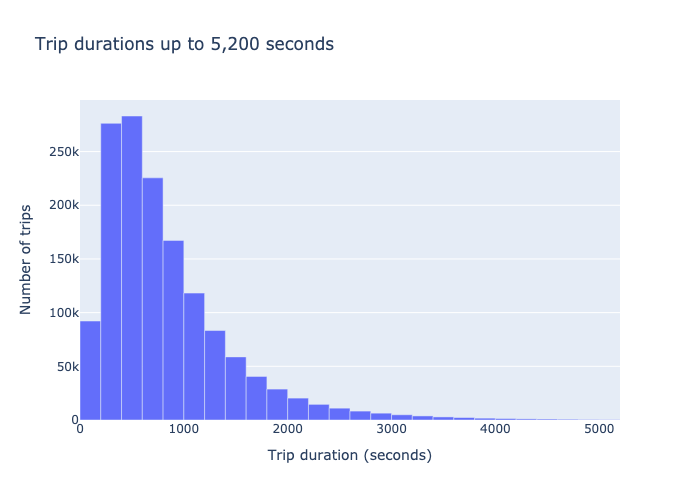

In [65]:
import plotly.express as px
import plotly.io as pio

pio.renderers.default = "plotly_mimetype+png" # Required to be able to export to PDF via nbconvert

# Load the taxi data again (not required)
# taxi_train = pd.read_csv("./data/nyc-taxi-train/train.csv")

plot_data = taxi_train_df.loc[
    taxi_train_df["trip_duration"].between(0, 5200)
]

reduce_notebook_size = True

if not reduce_notebook_size:
    fig = px.histogram(
        plot_data,
        x="trip_duration",
        title="Trip durations up to 5,200 seconds",
        labels={"trip_duration": "Trip duration (seconds)"},
    )

    fig.update_traces(xbins=dict(start=0, end=5200, size=200))
else:
    # Count trips in 200-second bins from 0 to 5,200
    durations = plot_data["trip_duration"].values
    counts, edges = np.histogram(
        durations,
        bins=np.arange(0, 5201, 200),
    )

    fig = px.bar(
        x=(edges[:-1] + edges[1:]) / 2,
        y=counts,
        title="Trip durations up to 5,200 seconds",
        labels={
            "x": "Trip duration (seconds)",
            "y": "Number of trips",
        },
    )

    fig.update_traces(width=np.diff(edges))
    fig.update_layout(bargap=0, xaxis_range=[0, 5200])
fig.show()

And with log transformation:

[numpy.log1p](https://numpy.org/doc/stable/reference/generated/numpy.log1p.html)

Return the natural logarithm of one plus the input array, element-wise.

Calculates `log(1 + x)`.

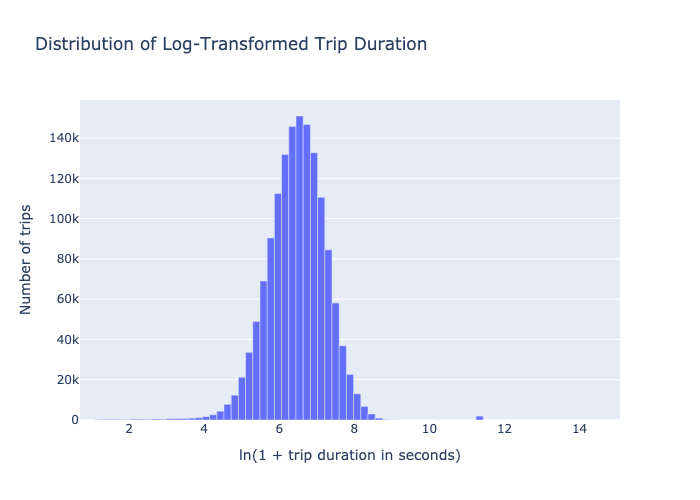

In [66]:
#taxi_train['log_trip_duration'] = taxi_train['trip_duration'].apply(lambda x: np.log(1+x))

taxi_train_df["log_trip_duration"] = np.log1p(taxi_train_df["trip_duration"])

number_of_bins=75

if not reduce_notebook_size:
    fig = px.histogram(
        taxi_train_df,
        x="log_trip_duration",
        nbins=number_of_bins,
        title="Distribution of Log-Transformed Trip Duration",
        labels={"log_trip_duration": "ln(1 + trip duration in seconds)"},
    )
else:
    counts, edges = np.histogram(
        taxi_train_df["log_trip_duration"].dropna(),
        bins=number_of_bins,
    )

    fig = px.bar(
        x=(edges[:-1] + edges[1:]) / 2,
        y=counts,
        title="Distribution of Log-Transformed Trip Duration",
        labels={
            "x": "ln(1 + trip duration in seconds)",
            "y": "Number of trips",
        },
    )

    fig.update_traces(width=np.diff(edges))
    fig.update_layout(bargap=0)

fig.show()

A log transformation on trip duration is much less skewed and thus much more helpful for a model.

This is also explained in section 25.4 of the book [Data Analysis Using Regression and Multilevel/Hierarchical Models (Final version: 5 July 2006)](http://www.stat.columbia.edu/~gelman/arm/missing.pdf?ref=jeremyjordan.me)

### Extra: plotting pickup and dropoff locations on a map

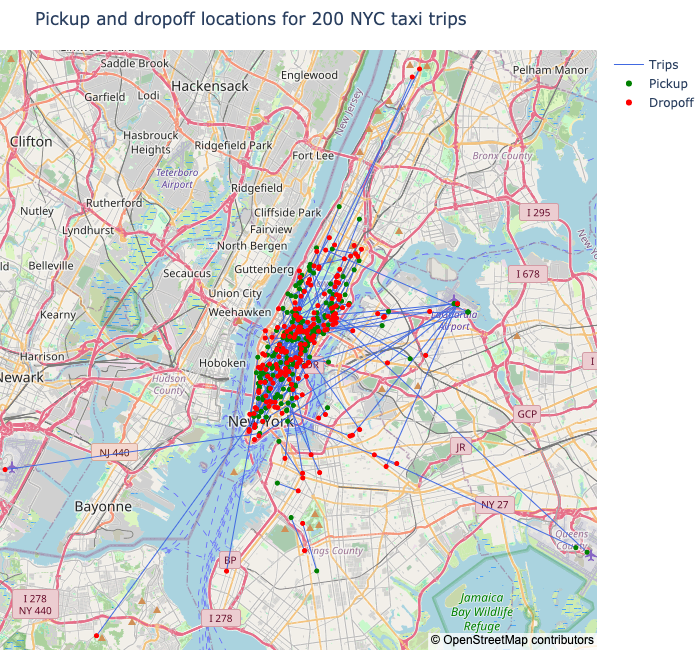

In [67]:
import plotly.graph_objects as go

# Keep coordinates within the NYC area and sample up to 200 trips
valid_trips = taxi_train_df.loc[
    taxi_train_df["pickup_latitude"].between(40.4, 41.0)
    & taxi_train_df["dropoff_latitude"].between(40.4, 41.0)
    & taxi_train_df["pickup_longitude"].between(-74.3, -73.6)
    & taxi_train_df["dropoff_longitude"].between(-74.3, -73.6)
]

trips = valid_trips.sample(
    n=min(200, len(valid_trips)),
    random_state=42,
)

# None separates consecutive trips so they aren't joined together
latitudes, longitudes = [], []

for trip in trips.itertuples():
    latitudes.extend([
        trip.pickup_latitude, trip.dropoff_latitude, None
    ])
    longitudes.extend([
        trip.pickup_longitude, trip.dropoff_longitude, None
    ])

fig = go.Figure()

fig.add_trace(go.Scattermapbox(
    lat=latitudes,
    lon=longitudes,
    mode="lines",
    line=dict(width=1, color="royalblue"),
    name="Trips",
    hoverinfo="skip",
))

for label, prefix, color in [
    ("Pickup", "pickup", "green"),
    ("Dropoff", "dropoff", "red"),
]:
    fig.add_trace(go.Scattermapbox(
        lat=trips[f"{prefix}_latitude"],
        lon=trips[f"{prefix}_longitude"],
        mode="markers",
        marker=dict(size=6, color=color),
        name=label,
        text=trips["id"],
        hovertemplate=f"{label}: %{{text}}<extra></extra>",
    ))

fig.update_layout(
    title=f"Pickup and dropoff locations for {len(trips)} NYC taxi trips",
    mapbox=dict(
        style="open-street-map",
        center=dict(lat=40.75, lon=-73.98),
        zoom=10,
    ),
    height=650,
    margin=dict(l=0, r=0, t=50, b=0),
)

fig.show()

The code to show all trips is

```bash
trips = taxi_train_df.dropna(subset=[
    "pickup_latitude",
    "pickup_longitude",
    "dropoff_latitude",
    "dropoff_longitude",
])
```

But this is a **terrrible idea**: 1.46 million lines plus pickup and dropoff markers will freeze the browser and make the notebook enormous. For displaying all trips, a rasterized visualization is more practical: it draws all the trips into an image without embedding millions of coordinates in the notebook output.

In fact, that's what it did and took me a long time to revert the situation as Pycharm refused to handle a file that is 699MB.

Let's try a rasterized visualization instead.

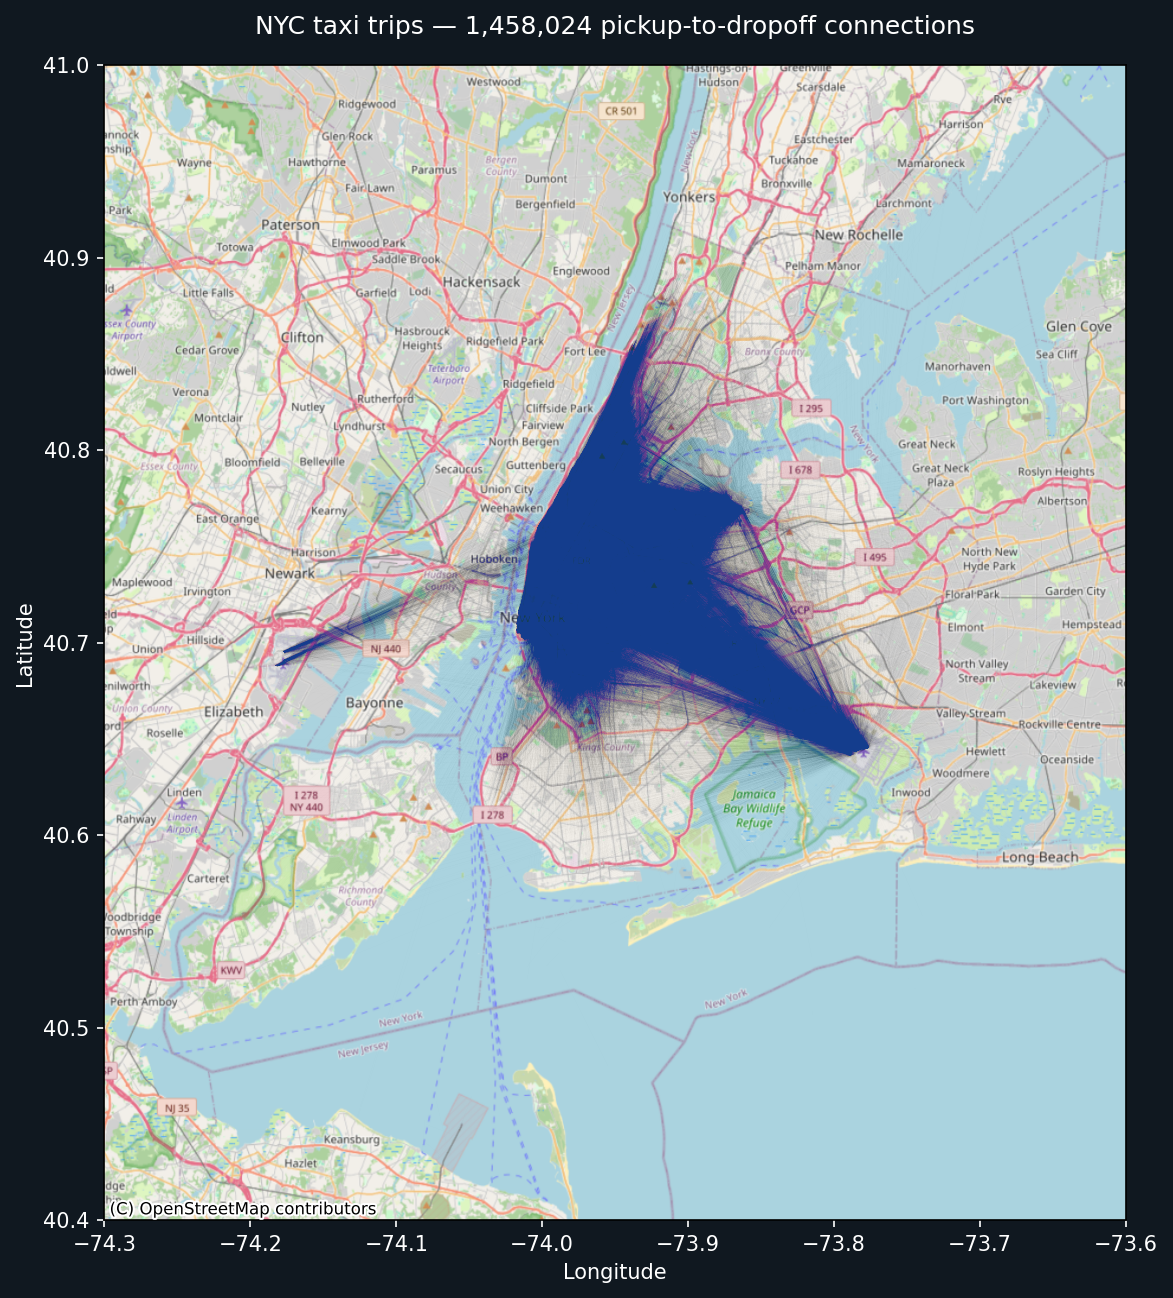

In [68]:
import io
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from pathlib import Path
import contextily as ctx

map_provider = "OpenStreetMap" # Options: "Carto", "OpenStreetMap". Open Street Maps look better

# NYC plotting bounds
lon_min, lon_max = -74.3, -73.6
lat_min, lat_max = 40.4, 41.0

mask = (
    taxi_train_df["pickup_longitude"].between(lon_min, lon_max)
    & taxi_train_df["dropoff_longitude"].between(lon_min, lon_max)
    & taxi_train_df["pickup_latitude"].between(lat_min, lat_max)
    & taxi_train_df["dropoff_latitude"].between(lat_min, lat_max)
)

# Each segment contains a pickup and dropoff coordinate pair
segments = taxi_train_df.loc[
    mask,
    [
        "pickup_longitude", "pickup_latitude",
        "dropoff_longitude", "dropoff_latitude",
    ],
].to_numpy().reshape(-1, 2, 2)

fig, ax = plt.subplots(figsize=(10, 10), dpi=150)
fig.patch.set_facecolor("#101820")
ax.set_facecolor("#101820")

lines = LineCollection(
    segments,
    colors="#42d4f4",
    linewidths=0.2,
    alpha=0.00700,
)
ax.add_collection(lines)

ax.set_xlim(lon_min, lon_max)
ax.set_ylim(lat_min, lat_max)

# Approximate geographic proportions at NYC's latitude
ax.set_aspect(1 / np.cos(np.radians(40.7)))

ax.set_title(
    f"NYC taxi trips — {len(segments):,} pickup-to-dropoff connections",
    color="white",
    pad=15,
)
ax.set_xlabel("Longitude", color="white")
ax.set_ylabel("Latitude", color="white")
ax.tick_params(colors="white")



if map_provider == "OpenStreetMap":
    cache_dir = Path("./data/map_tile_cache")
    cache_dir.mkdir(parents=True, exist_ok=True)
    ctx.set_cache_dir(str(cache_dir.resolve()))

    ctx.add_basemap(
        ax,
        source=ctx.providers.OpenStreetMap.Mapnik,
        crs="EPSG:4326",
        zoom=11,
        headers={
            "User-Agent": "IATD-Taxi-Notebook/1.0",
        },
        zorder=0,
    )
else:
    if map_provider == "Carto":
        from pathlib import Path
        from dotenv import dotenv_values
        from urllib.parse import quote

        config_path = Path(".env")

        if not config_path.is_file():
            raise FileNotFoundError(f"Configuration file not found: {config_path.resolve()}")

        config = dotenv_values(config_path)
        carto_key = config.get("CARTO_API_KEY")

        if carto_key is None:
            raise KeyError("CARTO_API_KEY is missing or has no value in .env")

        carto_key = carto_key.strip()

        if not carto_key:
            raise ValueError("CARTO_API_KEY is empty in .env")

        carto_url = (
            "https://basemaps.cartocdn.com/rastertiles/voyager/{z}/{x}/{y}.png"
            f"?key={quote(carto_key, safe='')}"
        )

        ctx.add_basemap(
            ax,
            source=carto_url,
            crs="EPSG:4326",
            zoom=11,
            zorder=0,
        )
    else:
        raise ValueError("Invalid map provider")


# Darker trip lines are easier to see on the light map
lines.set_color("#143d8d")
lines.set_zorder(2)

# Keep the trip lines above the map

# Explicitly display a raster image
with io.BytesIO() as buffer:
    fig.savefig(
        buffer,
        format="png",
        dpi=150,
        bbox_inches="tight",
        facecolor=fig.get_facecolor(),
    )
    plt.close(fig)
    display(Image(data=buffer.getvalue()))